# 2019 L-band cross-correlation with multiscale PCA (mPCA)

This recipe repeats the [2019 L-band cross-correlation](2019_Lband.ipynb) (MeerKLASS 2019 L-band × WiggleZ)
with the **multiscale PCA** (mPCA) foreground cleaning of
[Carucci et al. 2025, A&A 703, A222](https://doi.org/10.1051/0004-6361/202453461),
available as `meer21cm.mpca.mpca_clean`.

Standard PCA finds one set of foreground modes along frequency for all angular scales. mPCA first splits each
channel map into a **coarse** (large angular scales) and a **fine** (small angular scales) part with a starlet
wavelet transform, and runs a separate PCA on each, removing $N_{\rm L}$ modes from the coarse part and
$N_{\rm S}$ from the fine part:

$$\mathbf{d}_{\rm clean} = (I - A_{\rm L}A_{\rm L}^T)\,\mathbf{d}_{\rm coarse} + (I - A_{\rm S}A_{\rm S}^T)\,\mathbf{d}_{\rm fine}.$$

Large scales carry most of the foreground power and the instrumental systematics, small scales are closer to
thermal noise, so each scale gets its own level of cleaning. In the paper, mPCA with $(N_{\rm L}, N_{\rm S}) = (4, 8)$
gave the most significant detection of the cross-correlation (5.8σ, against 3.3σ for PCA with $N_{\rm fg} = 4$).

Data, all public: the MeerKLASS 2019 maps from [meerklass.org](https://meerklass.org/data.html), and the WiggleZ
11h-region galaxy catalogue `reg11data.dat` with its 10 random catalogues `reg11rand*.dat` from the WiggleZ release
on [Zenodo](https://zenodo.org/record/33470). The paper used a different version of the WiggleZ files (see
"Public data vs the paper's" below). Set-up as in the paper, and different from the 2019 L-band recipe:

- all 250 channels and the paper's "Conservative Footprint" (CF, stored in the pickle);
- galaxy field $F = D - \alpha R$ with randoms drawn from the WiggleZ selection function, and FKP weights with
  $P_0 = 1000\,h^{-3}{\rm Mpc}^3$;
- a Tukey ($\alpha = 0.5$) taper across the sky, on HI, galaxies and randoms;
- radial down-resolution 2 instead of 10.

**No transfer function.** All amplitudes below are therefore lower limits, for PCA and
mPCA alike. Errors are the Gaussian ones of the 2019 L-band recipe, which underestimate the real scatter.

In [1]:
import glob
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter, label
from scipy.signal.windows import tukey
from meer21cm import PowerSpectrum
from meer21cm.util import pca_clean, radec_to_indx
from meer21cm.mpca import mpca_clean, starlet_split
from meer21cm.telescope import dish_beam_sigma
from meer21cm.plot import plot_map, plot_eigenspectrum

In [2]:
file_dir = './'
pickle_file = file_dir + 'MK_2019_maps.pkl'                    # MeerKLASS 2019 maps (meerklass.org)
zenodo_dir = file_dir + 'data_from_zenodo/'                    # public WiggleZ release (Zenodo)
gal_file = zenodo_dir + 'reg11data.dat'
rand_files = sorted(glob.glob(zenodo_dir + 'reg11rand*.dat'))  # the 10 public random catalogues

ps = PowerSpectrum(
    pickle_file=pickle_file,
    beam_model='gaussian',
    beam_type='isotropic',
    band='L',
    survey='meerklass_2019',
)
ps.nu_min = 970e6  # the survey preset starts at 971 MHz and drops the first channel; keep all 250
ps.nu_max = 1024e6
ps.read_from_pickle()
ps.sigma_beam_ch = dish_beam_sigma(13.5, ps.nu)
galcat = np.genfromtxt(gal_file, skip_header=1)  # first line: number of objects; '#' lines are skipped
ra_g, dec_g, z_g = galcat[:, 0], galcat[:, 1], galcat[:, 2]
randcat = np.concatenate([np.genfromtxt(f, skip_header=1)[:, :3] for f in rand_files])
ra_r, dec_r, z_r = randcat[:, 0], randcat[:, 1], randcat[:, 2]
print(len(rand_files), 'random catalogues,', ra_r.size, 'randoms')
print(ps.data.shape, 'channels', ps.nu.min() / 1e6, '-', ps.nu.max() / 1e6, 'MHz')

filtering map los
10 random catalogues, 180190 randoms
(133, 41, 250) channels 970.94140625 - 1022.978515625 MHz


## Footprint

The CF is a 64 × 17 pixel rectangle in the middle of the scan, where the hits are high and uniform. Map, hits and
pixel weights are set to zero outside it; galaxies and randoms are kept if they fall in a CF pixel and in the
frequency band.
The band is 0.39 < z < 0.46, so only about a fifth of the WiggleZ galaxies in the CF are kept: the map below shows
far fewer galaxies than the one in the 2019 L-band recipe, which plots the whole catalogue at all redshifts.

2127 galaxies in the CF


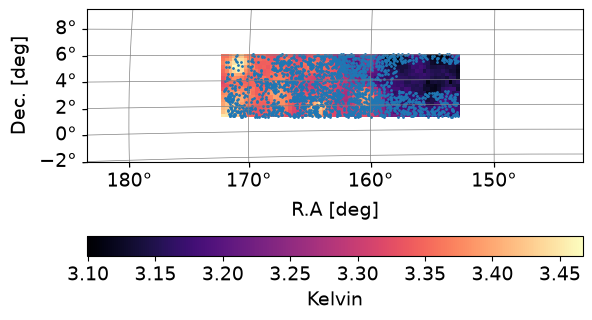

In [3]:
with open(pickle_file, 'rb') as f:
    CF = np.asarray(pickle.load(f)['CF_mask']) > 0
nz = ps.nu.size
CF3 = np.repeat(CF[:, :, None], nz, axis=-1)
ps.data = np.nan_to_num(ps.data) * CF3
ps.counts = np.nan_to_num(ps.counts) * CF3
ps.map_has_sampling = ps.map_has_sampling * CF3
ps.weights_map_pixel = ps.weights_map_pixel * CF3
ps.ra_range = np.array([ps.ra_map[CF].min() - 0.3, ps.ra_map[CF].max() + 0.3])
ps.dec_range = np.array([ps.dec_map[CF].min() - 0.3, ps.dec_map[CF].max() + 0.3])

nu_edges = np.concatenate([[1.5 * ps.nu[0] - 0.5 * ps.nu[1]], (ps.nu[1:] + ps.nu[:-1]) / 2,
                           [1.5 * ps.nu[-1] - 0.5 * ps.nu[-2]]])
z_edges = 1420.405751e6 / nu_edges - 1

def in_footprint(ra, dec, z):
    """Objects in a CF pixel and in the band, with their map pixel (ix, iy) and channel ich."""
    ix, iy = radec_to_indx(ra, dec, ps.wproj)
    ich = np.digitize(1420.405751e6 / (1 + z), nu_edges) - 1
    ok = (ix >= 0) & (ix < CF.shape[0]) & (iy >= 0) & (iy < CF.shape[1]) & (ich >= 0) & (ich < nz)
    inside = np.zeros(ra.size, dtype=bool)
    inside[ok] = CF[ix[ok], iy[ok]]
    return inside, ix[inside], iy[inside], ich[inside]

sel, gx, gy, gch = in_footprint(ra_g, dec_g, z_g)
ps._ra_gal, ps._dec_gal, ps._z_gal = ra_g[sel], dec_g[sel], z_g[sel]
print(sel.sum(), 'galaxies in the CF')

plt.rcParams.update({'font.size': 14})
plot_map(ps.data, ps.wproj, W=CF3, cbar_label='Kelvin')
ax = plt.gca()
ax.scatter(ps.ra_gal, ps.dec_gal, transform=ax.get_transform('world'), s=1)

## Public data vs the paper's

The paper used WiggleZ files obtained within the collaboration: a version of the 11h catalogue
(`wigglez_reg11hrS_z0pt30_0pt50`) and a selection function made from 1000 WiggleZ random catalogues, both gridded
on the 2019 map voxels. Compared with them, the public release used here:

- **misses a patch of sky inside the CF**: RA 152.9°–157.8°, Dec 3.2°–5.0°, about 105 CF pixels (~9.5 deg²,
  10 % of the CF), where the public catalogue and randoms are empty and the paper's catalogue has 190 galaxies in
  our band. The cell below finds the CF pixels without public randoms;
- therefore has **fewer galaxies**: 2127 in the CF and band against 2322 in the paper's catalogue. Outside the
  missing patch the two agree to better than 1 %, with the same redshift distribution;
- has only **10 random catalogues**, too few to use directly as randoms (next section).

Their redshifts line up with the paper's gridded galaxies channel by channel.

20375 public randoms in the CF; 121 of 1088 CF pixels have none: a patch of 106 pixels (10% of the CF; RA 152.9-157.8 deg, Dec 3.2-5.0 deg) and 15 isolated pixels


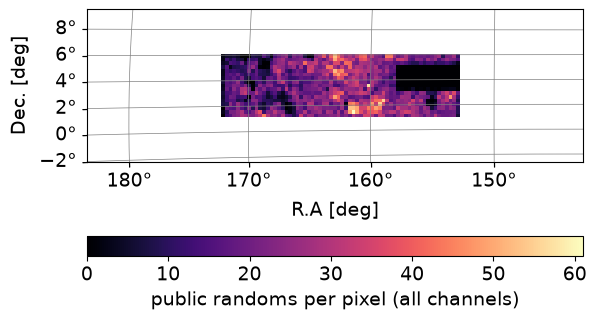

In [4]:
rsel, rx, ry, rch = in_footprint(ra_r, dec_r, z_r)
n_rand_pix = np.zeros(CF.shape)
np.add.at(n_rand_pix, (rx, ry), 1.0)
empty = CF & (n_rand_pix == 0)
labels, n_regions = label(empty)
patch = labels == np.argmax(np.bincount(labels.ravel())[1:]) + 1  # largest empty region
print(f'{rsel.sum()} public randoms in the CF; {empty.sum()} of {CF.sum()} CF pixels have none: '
      f'a patch of {patch.sum()} pixels ({patch.sum() / CF.sum():.0%} of the CF; '
      f'RA {ps.ra_map[patch].min():.1f}-{ps.ra_map[patch].max():.1f} deg, '
      f'Dec {ps.dec_map[patch].min():.1f}-{ps.dec_map[patch].max():.1f} deg) and {empty.sum() - patch.sum()} isolated pixels')
plot_map(n_rand_pix[:, :, None] * np.ones(nz), ps.wproj, W=CF3, cbar_label='public randoms per pixel (all channels)')

## The two scales

`starlet_split` returns the starlet scales of the maps (last axis: fine, then coarse; they sum to the input).
The coarse scale is the map smoothed with a B3-spline kernel of ~5 pixels; the fine scale is the rest.
`footprint` tells the transform which pixels are data; the others are filled before the transform and set to zero
after it.

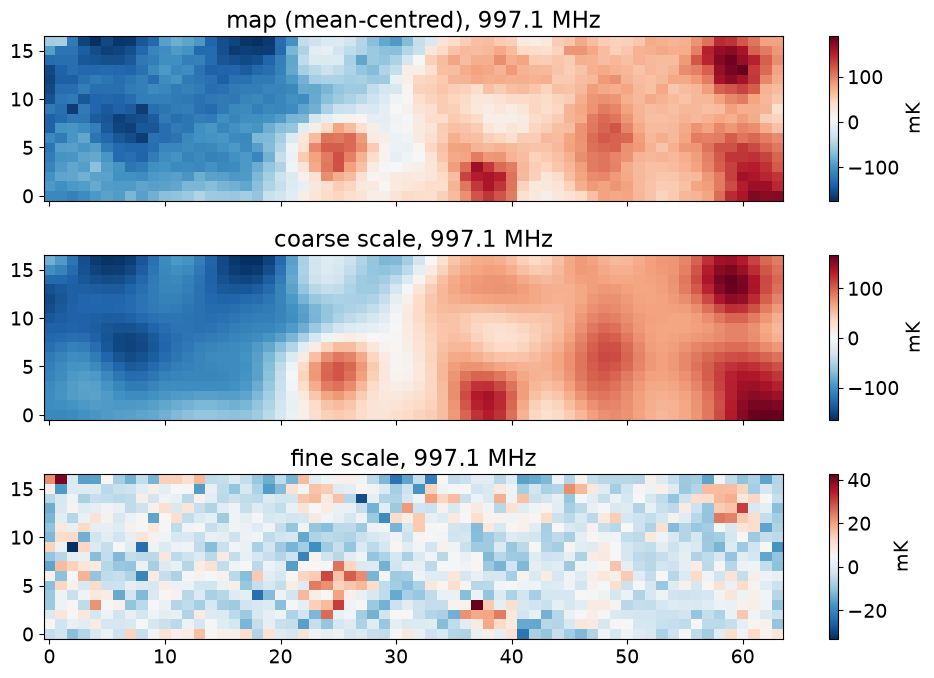

In [5]:
MKmap_orig = ps.data.copy()
ones_cf = CF3.astype(float)
from meer21cm.util import mean_center_signal
map_mc = mean_center_signal(MKmap_orig, ones_cf) * CF3  # mean-centred inside the CF
scales = starlet_split(map_mc, footprint=CF)
fine, coarse = scales[..., 0], scales[..., 1]

ch = nz // 2
sx, sy = np.where(CF)
box = (slice(sx.min(), sx.max() + 1), slice(sy.min(), sy.max() + 1))
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, m, t in zip(axes, [map_mc, coarse, fine], ['map (mean-centred)', 'coarse scale', 'fine scale']):
    im = ax.imshow(1e3 * m[box][:, :, ch].T, origin='lower', cmap='RdBu_r', aspect='auto')
    ax.set_title(f'{t}, {ps.nu[ch] / 1e6:.1f} MHz')
    plt.colorbar(im, ax=ax, label='mK')
plt.tight_layout()

Eigenvalues of the frequency-frequency covariance of the full maps and of each scale: most of the foreground power
is in the coarse scale; the fine scale has a shallower spectrum.

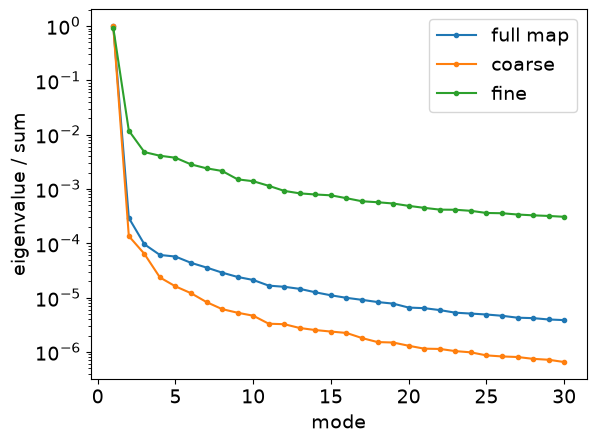

In [6]:
eig = {}
for name, m in [('full map', map_mc), ('coarse', coarse), ('fine', fine)]:
    _, _, eig[name], _ = pca_clean(m, 1, weights=ones_cf, return_analysis=True)
plt.figure()
for name, e in eig.items():
    plt.semilogy(np.arange(1, 31), e[:30] / e.sum(), 'o-', ms=3, label=name)
plt.xlabel('mode')
plt.ylabel('eigenvalue / sum')
plt.legend()

## Cleaning

PCA with $N_{\rm fg} = 4$ and mPCA with $(N_{\rm L}, N_{\rm S}) = (4, 8)$, the paper's best choices, both
mean-centred and unweighted inside the CF (`weights=ones_cf` keeps the zeros outside the CF out of the mean and
of the covariance; for mPCA `footprint=CF` does the same).

**Weighted variants.** The paper's PCAw and mPCAw weight each pixel by its hits **averaged along the line of
sight**, the same weight in every channel. Weights that change with frequency (e.g. the hits per channel, as in
the 2019 L-band recipe) mix modes along frequency before the PCA and change the removed modes. Here we build the
paper's weights by averaging the hits along frequency:

- mPCAw: `mpca_clean` with these weights and the unweighted mean (`mean_center_weights=ones_cf`), as in the paper;
- PCAw: the paper removed the mean of the *weighted* map before the covariance, which `pca_clean` does not do
  (it weights the mean-centred map), so we compute that covariance ourselves and pass it with `covariance=`.

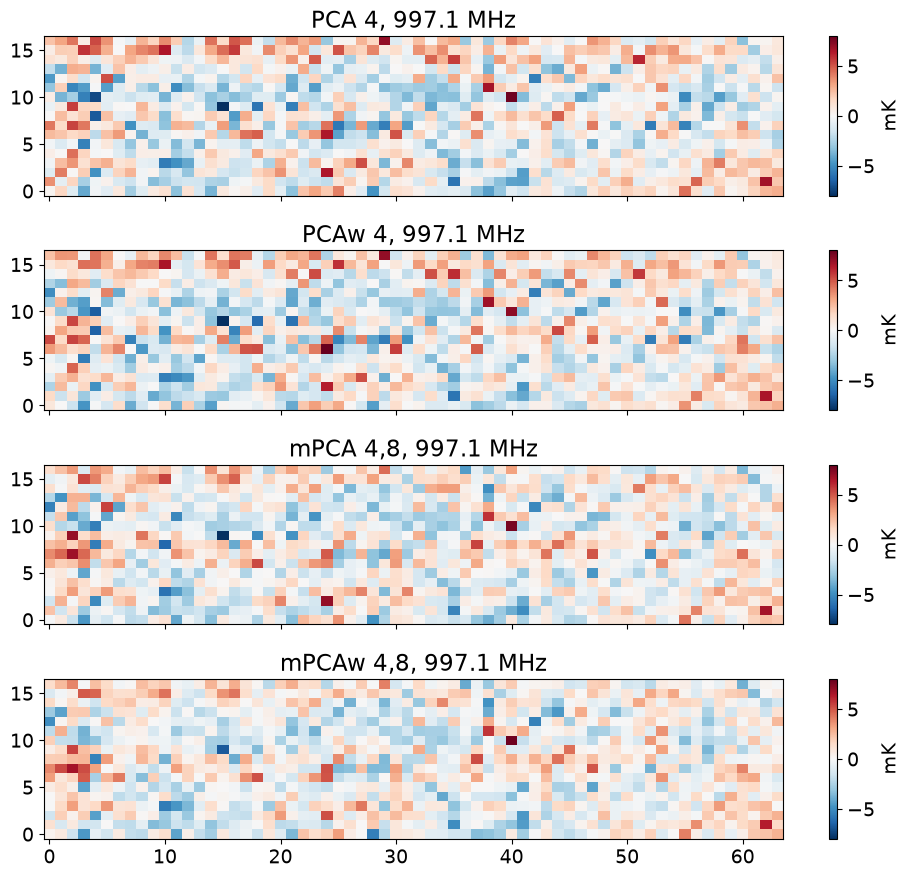

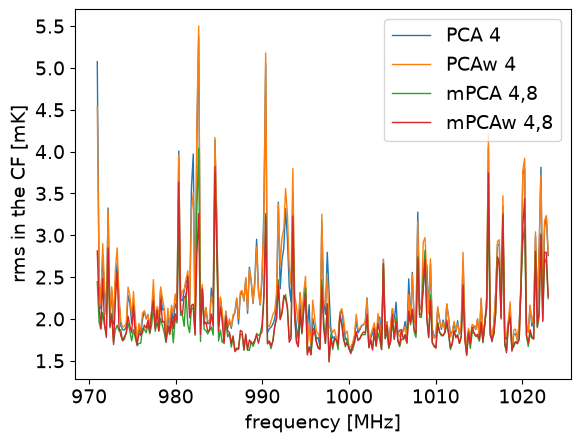

In [7]:
N_fg = 4
N_L, N_S = 4, 8
w_los = np.repeat(ps.counts.mean(axis=-1, keepdims=True), nz, axis=-1) * CF3  # hits averaged along frequency
y = (w_los * MKmap_orig)[CF]               # weighted maps, (n_pix, n_ch)
y = y - y.mean(axis=0)                     # mean of the weighted maps removed, as in the paper
cov_pcaw = y.T @ y
cleaned = {
    f'PCA {N_fg}': pca_clean(MKmap_orig, N_fg, weights=ones_cf, mean_center=True) * CF3,
    f'PCAw {N_fg}': pca_clean(MKmap_orig, N_fg, weights=ones_cf, mean_center=True, covariance=cov_pcaw) * CF3,
    f'mPCA {N_L},{N_S}': mpca_clean(MKmap_orig, N_L, N_S, mean_center=True, footprint=CF),
    f'mPCAw {N_L},{N_S}': mpca_clean(MKmap_orig, N_L, N_S, weights=w_los, mean_center=True,
                                     mean_center_weights=ones_cf),
}
fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for ax, (name, m) in zip(axes, cleaned.items()):
    im = ax.imshow(1e3 * m[box][:, :, ch].T, origin='lower', cmap='RdBu_r', aspect='auto', vmin=-8, vmax=8)
    ax.set_title(f'{name}, {ps.nu[ch] / 1e6:.1f} MHz')
    plt.colorbar(im, ax=ax, label='mK')
plt.tight_layout()

plt.figure()
for name, m in cleaned.items():
    plt.plot(ps.nu / 1e6, 1e3 * np.sqrt((m[CF] ** 2).mean(axis=0)), lw=1, label=name)
plt.xlabel('frequency [MHz]')
plt.ylabel('rms in the CF [mK]')
plt.legend()

## Selection function, randoms and galaxy weights

The galaxy field is $F = D - \alpha R$, with randoms $R$ that follow the WiggleZ selection function. We build the
selection function as a cube on the map voxels (pixel × channel), giving the expected number of galaxies in each:
the public randoms gridded on the CF voxels and smoothed with a 3D Gaussian (2 pixels, 10 channels), since there
are too few of them to use directly.

**Dense randoms.** meer21cm uses the painted $\alpha R$ on the box as the galaxy window. With only a few randoms
per box cell, their Poisson noise inflates the window normalisation and biases the amplitudes low (by ~40 % with
the ~20,000 public randoms in the CF). We therefore draw `oversample` × as many randoms as galaxies from the
selection cube: a Poisson number per voxel, placed uniformly inside it. The amplitudes are converged by
`oversample` ≈ 50.

FKP weights $w = 1/(1 + \bar n P_0)$ with $P_0 = 1000\,h^{-3}{\rm Mpc}^3$, as in the paper, with $\bar n$ the
selection cube divided by the voxel volume. Galaxies and randoms also get the Tukey taper across the sky that
multiplies the HI pixel weights.

The weighted and multiscale amplitudes are sensitive to the details of the selection function, at about the 1σ
level (e.g. how much it is smoothed), while PCA is not.

In [8]:
T2 = np.zeros(CF.shape)  # box: the CF rectangle, defined above
T2[box] = np.outer(tukey(box[0].stop - box[0].start, 0.5), tukey(box[1].stop - box[1].start, 0.5))
ps.weights_map_pixel = ps.weights_map_pixel * T2[:, :, None]

counts = np.zeros(CF3.shape)
np.add.at(counts, (rx, ry, rch), 1.0)
m3 = CF3.astype(float)
smooth = (2, 2, 10)  # pixels, pixels, channels
selection = gaussian_filter(counts, smooth, mode='constant') / np.maximum(
    gaussian_filter(m3, smooth, mode='constant'), 1e-12) * m3
selection *= sel.sum() / selection.sum()  # expected galaxies per voxel

oversample = 50
rng = np.random.default_rng(7)
n_r = rng.poisson(oversample * selection)
ii, jj, kk = np.nonzero(n_r)
ii, jj, kk = [np.repeat(a, n_r[ii, jj, kk]) for a in (ii, jj, kk)]
pix_deg = np.abs(ps.wproj.wcs.cdelt[0])
dnu = np.abs(np.diff(ps.nu).mean())
dec_r = ps.dec_map[ii, jj] + rng.uniform(-pix_deg / 2, pix_deg / 2, ii.size)
ra_r = ps.ra_map[ii, jj] + rng.uniform(-pix_deg / 2, pix_deg / 2, ii.size) / np.cos(np.deg2rad(ps.dec_map[ii, jj]))
z_r = 1420.405751e6 / (ps.nu[kk] + rng.uniform(-dnu / 2, dnu / 2, kk.size)) - 1
rs, rx, ry, rch = in_footprint(ra_r, dec_r, z_r)
ra_r, dec_r, z_r = ra_r[rs], dec_r[rs], z_r[rs]
print(ra_r.size, 'randoms drawn in the CF')

v_vox = ps.pix_resol_in_mpc**2 * ps.los_resol_in_mpc  # Mpc^3
nbar = selection / v_vox
P0 = 1000.0 / ps.h**3  # Mpc^3
w_gal = T2[gx, gy] / (1 + nbar[gx, gy, gch] * P0)
w_rand = T2[rx, ry] / (1 + nbar[rx, ry, rch] * P0)
print(f'nbar P0 in the CF: {(nbar[CF3] * P0).min():.2f} - {(nbar[CF3] * P0).max():.2f}')

106316 randoms drawn in the CF
nbar P0 in the CF: 0.01 - 0.87


## Gridding and power spectra

As in the 2019 L-band recipe, with a finer radial grid (down-resolution 2 instead of 10, which keeps more
line-of-sight modes) and the galaxy field $F = D - \alpha R$ (`construct_fkp=True`).

In [9]:
ps.downres_factor_transverse = 1.5
ps.downres_factor_radial = 2.0
ps.box_buffkick = [20, 20, 0]
ps.num_particle_per_pixel = 1
ps.grid_scheme = 'nnb'
ps.get_enclosing_box()
gal_field_rg, _, _ = ps.grid_gal_to_field(
    weights=w_gal, construct_fkp=True, random_radecz=(ra_r, dec_r, z_r), random_weights=w_rand,
)
print(f'alpha = {ps.field_2_alpha:.4f}')

def grid_hi(hi_map):
    ps.data = hi_map
    hi_map_rg, _, _ = ps.grid_data_to_field()
    return hi_map_rg

def set_fields(hi_map_rg):
    taper = ps.taper_func(ps.box_ndim[2])[None, None, :]
    ps.field_1 = hi_map_rg
    ps.weights_grid_1 = ps.counts_in_box.astype('float') * taper
    ps.weights_field_1 = None
    # field_2 = D - alpha R and weights_field_2 = alpha R were set by grid_gal_to_field
    ps.weights_grid_2 = np.ones(ps.box_ndim) * taper
    ps.mean_center_1, ps.mean_center_2 = False, False
    ps.unitless_1, ps.unitless_2 = False, False
    ps.sampling_resol = np.array([ps.pix_resol_in_mpc, ps.pix_resol_in_mpc, ps.los_resol_in_mpc])
    ps.compensate = True
    ps.include_sky_sampling = [True, False]

set_fields(grid_hi(cleaned[f'PCA {N_fg}']))
kbins = np.linspace(0.02, 0.3, 12) * ps.h  # the paper's k-bins, in Mpc^-1
k_sel = np.ones_like(ps.k_mode)
k_sel[0], k_sel[:, 0, :], k_sel[:, :, 0] = 0.0, 0.0, 0.0  # drop the zero planes
ps.k1dbins = kbins

# model for 10^3 Omega_HI b_HI r = 1, with b_g = sqrt(0.83) and RSD (1 + f mu^2)^2 as in the paper
b_g = np.sqrt(0.83)
ps.mean_amp_1 = 'average_hi_temp'
ps.tracer_bias_1, ps.tracer_bias_2, ps.cross_coeff = 1.0, 1.0, 1.0
ps.omega_hi = 1e-3
template, _, _ = ps.get_1d_power(ps.cross_power_tracer_model, k1dweights=k_sel)
template = b_g * template

alpha = 0.0201


In [10]:
def measure(hi_map):
    set_fields(grid_hi(hi_map))
    p_c, keff, nmodes = ps.get_1d_power(ps.cross_power_3d, k1dweights=k_sel)
    p_hi, _, _ = ps.get_1d_power(ps.auto_power_3d_1, k1dweights=k_sel)
    p_gg, _, _ = ps.get_1d_power(ps.auto_power_3d_2, k1dweights=k_sel)
    sigma = np.sqrt((p_c**2 + p_hi * p_gg) / 2) / np.sqrt(nmodes)  # Gaussian error, as in the 2019 recipe
    good = np.isfinite(p_c) & (sigma > 0)
    w = 1 / sigma[good] ** 2
    F = np.sum(template[good] ** 2 * w)
    A = np.sum(p_c[good] * template[good] * w) / F  # one-parameter least squares: p = A * template
    chi2 = np.sum((p_c[good] - A * template[good]) ** 2 * w)
    return dict(k=keff, p=p_c, sigma=sigma, A=A, sigma_A=1 / np.sqrt(F), chi2_dof=chi2 / (good.sum() - 1))

res = {name: measure(m) for name, m in cleaned.items()}
for name, r in res.items():
    print(f"{name:10s} 10^3 Omega_HI b_HI r = {r['A']:.2f} ± {r['sigma_A']:.2f}   chi2/dof = {r['chi2_dof']:.2f}")

PCA 4      10^3 Omega_HI b_HI r = 0.50 ± 0.15   chi2/dof = 2.87
PCAw 4     10^3 Omega_HI b_HI r = 0.66 ± 0.15   chi2/dof = 0.84
mPCA 4,8   10^3 Omega_HI b_HI r = 0.74 ± 0.14   chi2/dof = 0.80
mPCAw 4,8  10^3 Omega_HI b_HI r = 0.69 ± 0.14   chi2/dof = 0.81


Text(0.5, 1.0, 'weighted (hits averaged along the line of sight)')

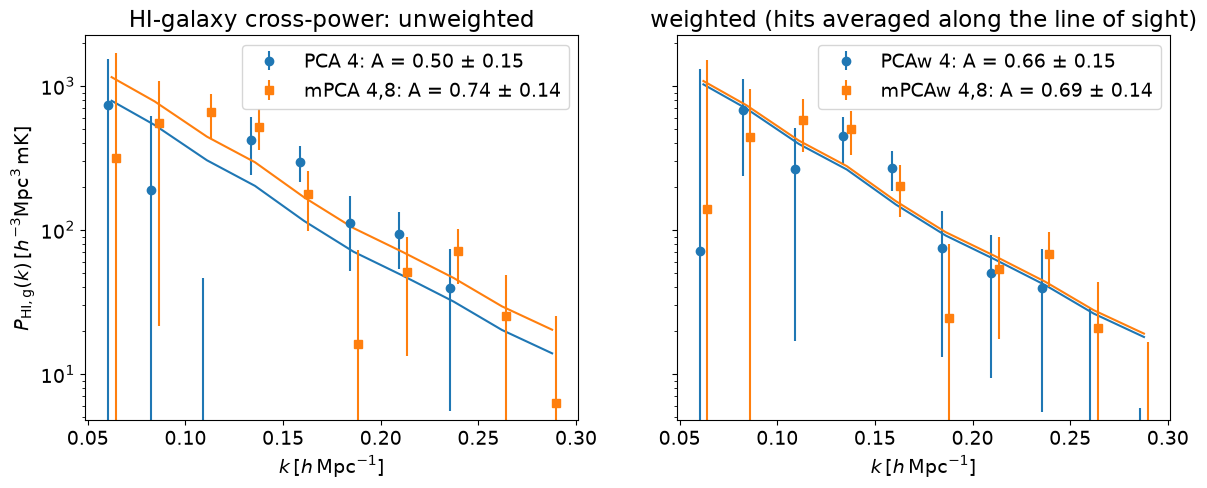

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, pair in zip(axes, [(f'PCA {N_fg}', f'mPCA {N_L},{N_S}'), (f'PCAw {N_fg}', f'mPCAw {N_L},{N_S}')]):
    for name, mk, dx in zip(pair, ['o', 's'], [-0.002, 0.002]):
        r = res[name]
        line = ax.errorbar(r['k'] / ps.h + dx, r['p'] * ps.h**3 * 1e3, yerr=r['sigma'] * ps.h**3 * 1e3,
                           ls='none', marker=mk, label=f"{name}: A = {r['A']:.2f} ± {r['sigma_A']:.2f}")
        ax.plot(r['k'] / ps.h, r['A'] * template * ps.h**3 * 1e3, color=line[0].get_color())
    ax.set_yscale('log')
    ax.set_xlabel(r'$k\,[h\,{\rm Mpc}^{-1}]$')
    ax.legend()
axes[0].set_ylabel(r'$P_{\rm HI,g}(k)\,[h^{-3}{\rm Mpc^3\,mK}]$')
axes[0].set_title('HI-galaxy cross-power: unweighted')
axes[1].set_title('weighted (hits averaged along the line of sight)')

Comparison with the paper (Table 1, Gaussian errors, no transfer function):

In [12]:
paper = {f'PCA {N_fg}': (0.50, 0.16), f'PCAw {N_fg}': (0.79, 0.17),
         f'mPCA {N_L},{N_S}': (0.93, 0.17), f'mPCAw {N_L},{N_S}': (0.87, 0.17)}
for name, r in res.items():
    print(f"{name:10s} this page: {r['A']:.2f} ± {r['sigma_A']:.2f}    paper: {paper[name][0]:.2f} ± {paper[name][1]:.2f}")

PCA 4      this page: 0.50 ± 0.15    paper: 0.50 ± 0.16
PCAw 4     this page: 0.66 ± 0.15    paper: 0.79 ± 0.17
mPCA 4,8   this page: 0.74 ± 0.14    paper: 0.93 ± 0.17
mPCAw 4,8  this page: 0.69 ± 0.14    paper: 0.87 ± 0.17


Why the numbers differ from the paper's:

- **galaxies and selection function**: the public WiggleZ files miss a 10 % patch of the CF (190 of the paper's
  galaxies) and come with only 10 random catalogues, from which the selection function has to be smoothed (see
  "Public data vs the paper's"). The weighted and multiscale amplitudes are sensitive to these details at about
  the 1σ level; PCA is not;
- **power-spectrum estimation**: the paper used its own pipeline; here gridding to the comoving box, galaxy field
  and window normalisation, model convolution, k-binning and fit are meer21cm's (as in the 2019 L-band recipe);
- **errors**: Gaussian here as in the paper's Table 1; they underestimate the real scatter (about 2× for these
  data, from galaxies shuffled along the line of sight).

Within these differences, the paper's main points hold: mPCA recovers more cross-correlation signal than PCA with a
better fit, and PCA with $N_{\rm fg} = 4$ agrees with the paper. That is to say, PCA does not depend on the galaxy catalogue.